In [21]:
# 앞에서 정의해 둔 것들
"""
Lab 4 공통 코드 (Lab 5에서 그대로 사용)

포함 내용
  1. device, seed
  2. 코퍼스(레스토랑 문장 47개), 단어장, special token
  3. LanguageModelDataset, loader
  4. train_model (Lab 5 슬라이드 20용으로 losses 반환하도록 수정)
  5. generate_text (temperature + top-k)
  6. RNNLanguageModel, LSTMLanguageModel (Lab 5 슬라이드 18~20 비교용)
"""
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

# ---------------------------------------------------------------
# 1. device, seed
# ---------------------------------------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(42)

# ---------------------------------------------------------------
# 2. 코퍼스와 단어장
# ---------------------------------------------------------------
sentences = [
    "i want chinese food", "i want korean food", "i want italian food", "i want japanese food",
    "i want thai food", "i want indian food", "i want a chinese restaurant", "i want a korean restaurant",
    "i want an italian restaurant", "i want a japanese restaurant", "i want to eat chinese food",
    "i want to eat korean food", "i want to eat italian food", "i want to eat japanese food",
    "i would like chinese food", "i would like korean food", "i would like italian food",
    "i would like japanese food", "find a chinese restaurant", "find a korean restaurant",
    "find an italian restaurant", "find a japanese restaurant", "show me a chinese restaurant",
    "show me a korean restaurant", "show me an italian restaurant", "show me a japanese restaurant",
    "can you find a chinese restaurant", "can you find a korean restaurant",
    "can you find an italian restaurant", "can you find a japanese restaurant",
    "where can i eat chinese food", "where can i eat korean food", "where can i eat italian food",
    "where can i eat japanese food", "i want cheap chinese food", "i want cheap korean food",
    "i want expensive italian food", "find a cheap restaurant", "find a good restaurant",
    "find a nearby restaurant", "i want a restaurant downtown", "i want a restaurant nearby",
    "show me a restaurant downtown", "the chinese restaurant is good", "the korean restaurant is good",
    "the italian restaurant is expensive", "the thai restaurant is cheap",
]

SPECIAL_TOKENS = ["<pad>", "<bos>", "<eos>", "<unk>"]

words = []
for sentence in sentences:
    words.extend(sentence.lower().split())

vocab = SPECIAL_TOKENS + sorted(set(words))
word_to_id = {word: i for i, word in enumerate(vocab)}
id_to_word = {i: word for word, i in word_to_id.items()}

PAD_ID = word_to_id["<pad>"]   # 0
BOS_ID = word_to_id["<bos>"]   # 1
EOS_ID = word_to_id["<eos>"]   # 2
UNK_ID = word_to_id["<unk>"]   # 3
vocab_size = len(vocab)        # 33

MAX_LEN = 12


# ---------------------------------------------------------------
# 3. Dataset (x와 y가 한 칸씩 밀린 다음 단어 예측 데이터)
# ---------------------------------------------------------------
class LanguageModelDataset(Dataset):
    def __init__(self, sentences, max_len=None):
        max_len = max_len or MAX_LEN
        self.examples = []
        for sentence in sentences:
            ids = [BOS_ID]
            for word in sentence.lower().split():
                ids.append(word_to_id.get(word, UNK_ID))
            ids.append(EOS_ID)

            x = ids[:-1][:max_len]   # <bos> i want chinese food
            y = ids[1:][:max_len]    # i want chinese food <eos>

            padding = max_len - len(x)
            x = x + [PAD_ID] * padding
            y = y + [PAD_ID] * padding

            self.examples.append((
                torch.tensor(x, dtype=torch.long),
                torch.tensor(y, dtype=torch.long),
            ))

    def __len__(self):
        return len(self.examples)

    def __getitem__(self, index):
        return self.examples[index]


dataset = LanguageModelDataset(sentences)
loader = DataLoader(dataset, batch_size=16, shuffle=True)


# ---------------------------------------------------------------
# 4. 학습 함수 (epoch별 평균 loss 리스트를 반환)
# ---------------------------------------------------------------
def train_model(model, loader, epochs=200, learning_rate=0.003):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss(ignore_index=PAD_ID)
    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)
    model.train()

    losses = []
    for epoch in range(epochs):
        total_loss = 0
        for x, y in loader:
            x = x.to(device)
            y = y.to(device)

            optimizer.zero_grad()
            logits = model(x)                                # [B, T, V]
            loss = criterion(
                logits.reshape(-1, logits.size(-1)),         # [B*T, V]
                y.reshape(-1),                               # [B*T]
            )
            loss.backward()
            optimizer.step()
            total_loss += loss.item()

        average_loss = total_loss / len(loader)
        losses.append(average_loss)
        if (epoch + 1) % 50 == 0:
            print(f"Epoch: {epoch + 1:3d}, Loss: {average_loss:.4f}")

    return losses


# ---------------------------------------------------------------
# 5. 텍스트 생성 (temperature + top-k)
# ---------------------------------------------------------------
def generate_text(model, prompt="i want", max_new_tokens=12, temperature=0.8, top_k=3):
    model.eval()
    ids = [BOS_ID]
    for word in prompt.lower().split():
        ids.append(word_to_id.get(word, UNK_ID))

    with torch.no_grad():
        for _ in range(max_new_tokens):
            context = ids[-MAX_LEN:]
            x = torch.tensor([context], dtype=torch.long, device=device)   # [1, len]
            logits = model(x)                                              # [1, len, V]
            next_logits = logits[0, -1] / temperature                      # [V]

            if top_k is not None:
                values, indices = torch.topk(next_logits, top_k)
                probabilities = F.softmax(values, dim=-1)
                sampled_index = torch.multinomial(probabilities, 1)
                next_id = indices[sampled_index].item()
            else:
                probabilities = F.softmax(next_logits, dim=-1)
                next_id = torch.multinomial(probabilities, 1).item()

            if next_id == EOS_ID:
                break
            ids.append(next_id)

    generated_words = [id_to_word[i] for i in ids if id_to_word[i] not in SPECIAL_TOKENS]
    return " ".join(generated_words)


# ---------------------------------------------------------------
# 6. Lab 4 모델 (Lab 5 슬라이드 18~20에서 4개 모델 비교용)
# ---------------------------------------------------------------
class RNNLanguageModel(nn.Module):
    def __init__(self, vocab_size, embedding_dim=64, hidden_dim=128):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=PAD_ID)
        self.rnn = nn.RNN(embedding_dim, hidden_dim, batch_first=True)
        self.output = nn.Linear(hidden_dim, vocab_size)

    def forward(self, x):
        embedded = self.embedding(x)           # [B, T, E]
        hidden_states, _ = self.rnn(embedded)  # [B, T, H]
        return self.output(hidden_states)      # [B, T, V]


class LSTMLanguageModel(nn.Module):
    def __init__(self, vocab_size, embedding_dim=64, hidden_dim=128):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=PAD_ID)
        self.lstm = nn.LSTM(embedding_dim, hidden_dim, batch_first=True)
        self.output = nn.Linear(hidden_dim, vocab_size)

    def forward(self, x):
        embedded = self.embedding(x)
        hidden_states, _ = self.lstm(embedded)
        return self.output(hidden_states)

# **과제: Attention Weight 시각화 및 분석**

# **목적: 학습된 Single-head Attention 모델에서 각 단어가 이전 단어들을 얼마나 참조하는지 확인한다.**

기존 AttentionLanguageModel과 학습된 attention_model을 사용하여 다음 작업을 수행하시오.

1. Attention Weight 추출

기존 forward() 함수를 수정하여 logits와 attention_weights를 반환할 수 있도록 한다.

입력 문장은 "<bos> i want chinese"로 한다.

attention_weights의 Tensor 크기를 출력한다.

2. Attention Weight 시각화 (첨부의 그림 참조)

Matplotlib의 imshow()를 이용하여 Attention Weight를 Heatmap으로 표시한다.

X축과 Y축에는 입력 단어를 표시한다.

3. 결과 해석

왜 Attention Matrix의 오른쪽 위 영역은 0에 가까운 값을 갖는가?

"chinese" 위치에서는 어떤 단어들을 참조할 수 있는가?

In [22]:
import math
import torch
import torch.nn as nn

# B	- batch_size / T - seq_len / d	- embedding_dim

class AttentionLanguageModel(nn.Module):
    def __init__(
        self,
        vocab_size,                 # 어휘 사전의 크기
        embedding_dim=64,           # 임베딩 벡터 차원 (d)
        max_len=MAX_LEN          # 최대 시퀀스 길이
    ):
        super().__init__()

        self.embedding_dim = embedding_dim

        # 1. 토큰 임베딩 레이어: 단어 ID → d차원 벡터 (vocab_size × d 크기의 표)
        self.token_embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=PAD_ID
        )

        # 2. 위치 임베딩 레이어: Attention은 순서를 모르므로 위치 정보를 따로 더해줌
        #    위치 0 ~ max_len-1 각각에 학습 가능한 벡터 하나씩
        self.position_embedding = nn.Embedding(
            max_len,
            embedding_dim
        )

        # 3. 같은 h를 Q(찾는 것), K(라벨), V(내용) 세 역할로 변환하는 선형 레이어
        self.query = nn.Linear(embedding_dim, embedding_dim, bias=False)
        self.key = nn.Linear(embedding_dim, embedding_dim, bias=False)
        self.value = nn.Linear(embedding_dim, embedding_dim, bias=False)

        # 4. 출력 레이어: context 벡터(d) -> 단어장 각 단어의 점수(vocab_size)
        self.output = nn.Linear(embedding_dim, vocab_size)

    def forward(self, x,return_weights=False):                                       # x: (B, T)
        batch_size, seq_len = x.shape

        # 위치 인덱스 [0, 1, ..., T-1] 생성
        positions = torch.arange(
            seq_len,
            device=x.device
        )                                                       # (T,)
        # (T,) → (1, T): token embedding에 맞춰 배치 방향으로 브로드캐스팅하기 위해
        positions = positions.unsqueeze(0)                      # (1, T)

        # 토큰 임베딩 + 위치 임베딩 = "어떤 단어인가 + 몇 번째 자리인가" 둘을 더하기
        h = (
            self.token_embedding(x) +                           # (B, T, d)
            self.position_embedding(positions)                  # (1, T, d) → 브로드캐스팅
        )                                                       # (B, T, d)

        # Query, Key, Value 계산
        Q = self.query(h)                                       # (B, T, d)
        K = self.key(h)                                         # (B, T, d)
        V = self.value(h)                                       # (B, T, d)

        # 어텐션 점수: 모든 단어 쌍의 Q와 K 내적 = 유사도
        scores = torch.matmul(
            Q,
            K.transpose(-2, -1)  # 마지막 두 차원(T, d)만 뒤집어 (B, d, T)로 → 행렬곱 가능하게
        )                                                       # (B, T, T)

        # 분산을 1 근처로 유지 → softmax가 한 칸에 몰리는 것(기울기 소실) 방지  =>  스케일링
        scores = scores / math.sqrt(self.embedding_dim)        # (B, T, T)

        # Causal Masking: 대각선 위쪽(미래 단어)을 True로 -> -inf로 채워 미래 참조(커닝) 차단
        causal_mask = torch.triu(
            torch.ones(
                seq_len,
                seq_len,
                device=x.device,
                dtype=torch.bool
            ),
            diagonal=1
        )                                                       # (T, T)
        scores = scores.masked_fill(
            causal_mask,
            float('-inf')
        )

        # Padding Masking: PAD인 열(Key)을 가려 어떤 단어도 PAD를 보지 못하게 함
        # (B, T) → (B, 1, T): 가운데 1이 모든 행(Query)으로 브로드캐스팅되어 PAD 열 전체가 가려짐 -> PAD 위치의 열이 위에서 아래까지 한 번에 가려짐
        padding_mask = (x == PAD_ID).unsqueeze(1)            # (B, 1, T)
        scores = scores.masked_fill(padding_mask, float("-inf"))

        # 각 행(Query)의 합이 1인 확률로 변환, -inf는 가중치 0이 됨!
        attn_weights = torch.softmax(scores, dim=-1)            # (B, T, T)

        # 가중치 비율대로 V를 섞어 문맥이 반영된 Context Vector 생성
        context = torch.matmul(attn_weights, V)                 # (B, T, d)

        # 각 위치에서 다음 토큰을 예측하기 위한 로짓
        logits = self.output(context)                           # (B, T, vocab_size)

        if return_weights:
            return logits, attn_weights

        return logits

In [23]:
attention_model = AttentionLanguageModel (
    vocab_size=vocab_size,
).to(device)

att_loss = train_model(
    attention_model,
    loader,
    epochs=250
)

# HW5 1번 Attention Weight 추출
input_words = ["<bos>", "i", "want", "chinese"]
input_ids = [word_to_id[w] for w in input_words]
x = torch.tensor([input_ids], dtype=torch.long, device=device)   # (1, 4): 배치 차원 추가

attention_model.eval()
with torch.no_grad():
    logits, attention_weights = attention_model(x, return_weights=True)

print("logits shape:", logits.shape)
print("attention_weights shape:", attention_weights.shape)
print(attention_weights[0])
# print(logits[0])

Epoch:  50, Loss: 0.7752
Epoch: 100, Loss: 0.7360
Epoch: 150, Loss: 0.7057
Epoch: 200, Loss: 0.6704
Epoch: 250, Loss: 0.6690
logits shape: torch.Size([1, 4, 33])
attention_weights shape: torch.Size([1, 4, 4])
tensor([[1.0000, 0.0000, 0.0000, 0.0000],
        [0.4260, 0.5740, 0.0000, 0.0000],
        [0.3662, 0.0850, 0.5488, 0.0000],
        [0.0478, 0.0285, 0.0685, 0.8552]])


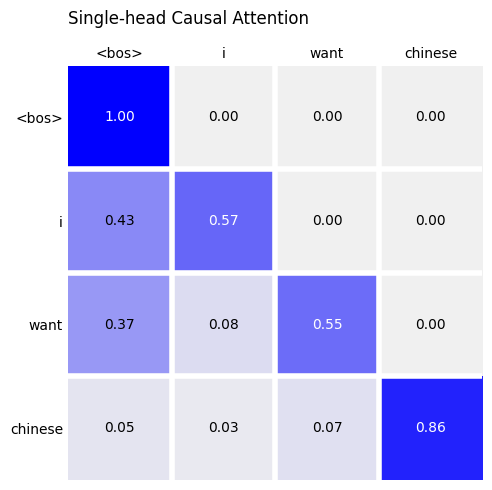

In [24]:
# HW5 2번 Attention Weight 시각화
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

weights = attention_weights[0].cpu().numpy()     # (4, 4)

cmap = LinearSegmentedColormap.from_list("attn", ["#f0f0f0", "#0000FF"])

fig, ax = plt.subplots(figsize=(8, 5))
ax.imshow(weights, cmap=cmap, vmin=0, vmax=1)

# X축 라벨을 위쪽으로
ax.xaxis.tick_top()
ax.set_xticks(range(len(input_words)))
ax.set_yticks(range(len(input_words)))
ax.set_xticklabels(input_words)
ax.set_yticklabels(input_words)
ax.tick_params(length=0)

# 칸 사이 흰 줄
ax.set_xticks([i - 0.5 for i in range(1, len(input_words))], minor=True)
ax.set_yticks([i - 0.5 for i in range(1, len(input_words))], minor=True)
ax.grid(which="minor", color="white", linewidth=4)
ax.tick_params(which="minor", length=0)
for spine in ax.spines.values():
    spine.set_visible(False)

# 각 칸에 숫자
for i in range(len(input_words)):
    for j in range(len(input_words)):
        ax.text(j, i, f"{weights[i, j]:.2f}", ha="center", va="center",
                color="white" if weights[i, j] > 0.5 else "black")

ax.set_title("Single-head Causal Attention", loc="left", pad=30)
plt.tight_layout()
plt.show()

# 왜 Attention Matrix의 오른쪽 위 영역은 0에 가까운 값을 갖는가?

코잘 마스크를 사용해서 torch.triu( ~ , diagonal = 1 )을 사용해서 대각선 위쪽을 True로 하고, 해당 점수를 -inf로 하여 softmax를 통해서 가중치 0을 만들어서, 실제 단어를 생성하는 과정에서는 미래(다음에 오는)단어가 없기 때문에 훈련에서도 미래 단어를 보고 베끼지 않도록 마스킹을 하기 위해서 가중치 0인 값을 가지도록 한다.

# “chinese” 위치에서는 어떤 단어들을 참조할 수 있는가?

chinese 위치에서는 이전 단어 4가지 모두를 참조할 수 있다.